# Hall-Petch equation exercise

A copper-zinc alloy has the following properties:

- For a grain size of 0.015 mm it has a yield strength of 170 MPa.
- For a grain size of 0.0035 mm it has a yield strength of 151 MPa.

Make a graph of yield strength vs grain size so that it's easy to interpolate or extrapolate for a datum.

In [0]:
size1 = 0.015 # mm
yield_strength1 = 170 # MPa
size2 = 0.0035 # mm
yield_strength2 = 151 # MPa

The Hall-Petch equation reads

$$ \sigma_y = \sigma_0 + Kd^{-1/2}  $$

Where

- $\sigma_y$ is the yield strength.
- $\sigma_0$ and $K$ are constants for the metal.
- $d$ is the grain size.

We'll start by converting the given sizes from mm to mm$^{-1/2}$

In [2]:
import numpy as np

inv_sqrt_d1 = np.power(size1, -0.5)
inv_sqrt_d2 = np.power(size2, -0.5)

print('d1^(-1/2):', inv_sqrt_d1)
print('d2^(-1/2):', inv_sqrt_d2)

d1^(-1/2): 8.16496580927726
d2^(-1/2): 16.903085094570333


Now we'll perform linear regression with these values

In [3]:
import scipy.stats

x = np.array([inv_sqrt_d1, inv_sqrt_d2])
y = np.array([yield_strength1, yield_strength2])
K, sigma_0, _, _, _ = scipy.stats.linregress(x, y)

print('sigma_0:', sigma_0)
print('K:', K)

sigma_0: 187.7537460077217
K: -2.174380937094606


Let's construct the linear graph

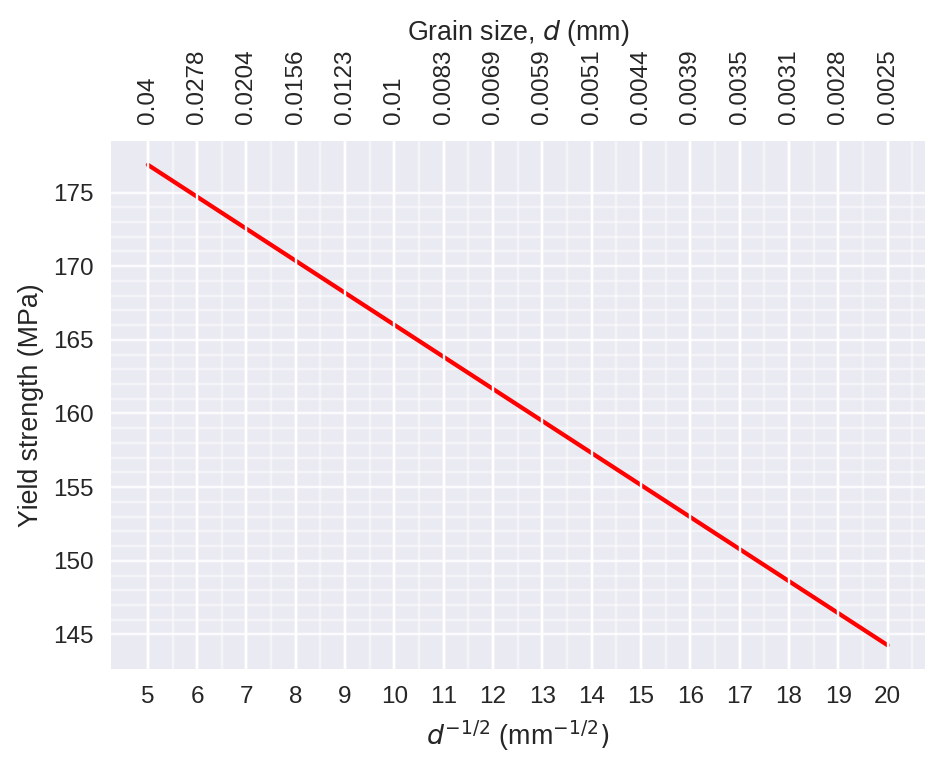

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline

x = np.linspace(5, 20)
y = sigma_0 + K * x

fig = plt.figure(dpi=175)
ax = fig.add_subplot(1, 1, 1)
top_ticks_ax = ax.twiny()

# Major ticks every 1, minor ticks every 5
x_major_ticks = np.arange(5, 21, 1)
x_minor_ticks = np.arange(5, 21, 0.5)
ax.set_xticks(x_major_ticks)
ax.set_xticks(x_minor_ticks, minor=True)

# Major ticks every 1, minor ticks every 5
y_major_ticks = np.arange(145, 176, 5)
y_minor_ticks = np.arange(145, 176, 1)
ax.set_yticks(y_major_ticks)
ax.set_yticks(y_minor_ticks, minor=True)

# And a corresponding grid
ax.grid(which='both')

# Or if you want different settings for the grids:
ax.grid(which='minor', alpha=0.5)
ax.grid(which='major', alpha=0.7)

ax.plot(x, y, 'r-')
ax.set_xlabel('$d^{-1/2}$ (mm$^{-1/2})$')
ax.set_ylabel('Yield strength (MPa)');

top_ticks = x_major_ticks.astype(float)
top_ticks_labels = np.round(np.power(top_ticks, -2), decimals=4)

top_ticks_ax.set_xlim(ax.get_xlim())
top_ticks_ax.set_xticks(top_ticks)
top_ticks_ax.set_xticklabels(top_ticks_labels, rotation='vertical')
top_ticks_ax.set_xlabel('Grain size, $d$ (mm)');

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# To make your graphics nicer
plt.rc('font', family='serif', size=16)
plt.rc('lines', linewidth=1.5)
plt.rc('legend', fontsize=12)

#===============================================================
# Define parameters
#===============================================================
Nx = 101                          # Number of grid points
xmax = 2.                         # Domain limit to the right
xmin = -2.                        # Domain limit to the left
Lx = xmax-xmin                    # Domain size
dx = Lx/(Nx-1)                    # Mesh size
x = np.linspace(xmin,xmax,Nx)     # Discretized mesh
dt = 0.04                         # Time step
t_end = 5.                        # Final time
Nt = int(t_end/dt)                # Number of iterations
a = 0.8                           # Advection speed
CFL = a*dt/dx                     # CFL number
U = np.zeros((Nt+1,Nx))           # u^n_i
U[0,:] = np.exp(-0.5*(x/0.4)**2)  # Initial solution
Uex = U[0,:]                      # Exact solution

#===============================================================
# Solve equation using the upwind scheme
#===============================================================
for n in range (0,Nt):

  if (a>0.):
      for i in range (1,Nx):    
          U[n+1,i] = U[n,i] - CFL*(U[n,i]-U[n,i-1]);
      U[n+1,0] = U[n+1,Nx-1];
  else:
      for i in range (0,Nx-1):
          U[n+1,i] = U[n,i] - CFL*(U[n,i+1]-U[n,i]);
      U[n+1,Nx-1] = U[n+1,0];
      
#===============================================================
# Compute exact solution
#===============================================================
  d = a*(n+1)*dt
  Uex = np.exp(-0.5*(np.mod(x-d+xmax,4)-xmax)**2/0.4**2)
  errL1 = U - Uex
  errL2 = np.linalg.norm(errL1)

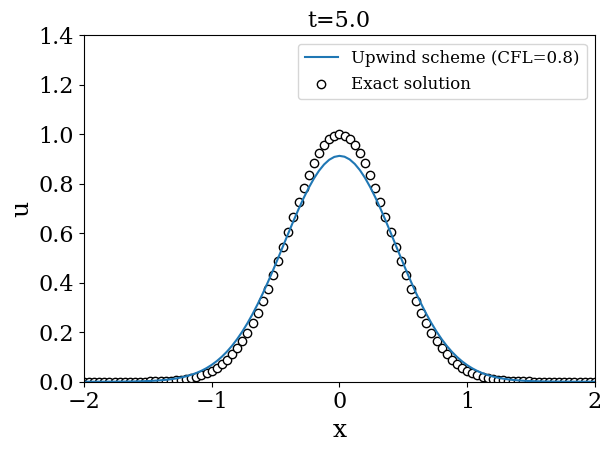

In [ ]:
#===============================================================
# Plot solution
#===============================================================
if (n==0): fig, ax = plt.subplots(figsize=(5.5,4))
plt.clf()
plt.plot(x,U[n+1,:])
plt.scatter(x,Uex, marker='o', facecolors='white', color='k')
plt.gca().legend(('Upwind scheme (CFL='+str(CFL)+')','Exact solution'))
plt.axis([xmin, xmax, 0, 1.4])
plt.title('t='+str(round(dt*(n+1),3)),fontsize=16)
plt.xlabel('x',fontsize=18)
plt.ylabel('u',fontsize=18)
plt.tight_layout()
plt.draw(); plt.pause(0.001)

plt.show()
#fig.savefig("figure.pdf", dpi=300)
#print 'Error L2 = ',errL2
# https://github.com/psvolpiani/YouTube-CFD-101/blob/main/01_advection_problem_upwind/01_cfd.py